### Passo 1: Montar o Google Drive
Primeiro, precisamos montar o Google Drive para conseguir acessar os seus arquivos diretamente do notebook.

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Passo 2: Carregar o DataFrame e Verificar os Tipos
Agora vamos ler o arquivo `clientes_base.csv` que está no caminho `My Drive/UNIPDS/clientes_base.csv`, exibir as primeiras linhas e os tipos de dados das colunas.

In [30]:
import pandas as pd
import os

# Caminho padrão para a pasta UNIPDS no seu Google Drive
caminho_arquivo = '/content/drive/My Drive/UNIPDS/clientes_base.csv'

if os.path.exists(caminho_arquivo):
    # Carrega o CSV
    df = pd.read_csv(caminho_arquivo)

    # Exibe o DataFrame
    print("--- Primeiras Linhas do DataFrame ---")
    display(df.head())

    # Exibe os tipos de colunas
    print("\n--- Tipos das Colunas ---")
    display(df.dtypes)
else:
    print(f"Erro: Arquivo não encontrado no caminho: {caminho_arquivo}")
    print("Por favor, verifique se o nome da pasta (UNIPDS) ou do arquivo está correto no seu Drive.")

--- Primeiras Linhas do DataFrame ---


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Tipos das Colunas ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,object
data_cancelamento,object


### Passo 3: Valores Únicos e Gráficos de Barras
Vamos analisar a distribuição de dados nas colunas `plano`, `ciclo`, `regiao` e `canal_aquisicao` usando tabelas de contagem e gráficos de barras.


=== Análise da Coluna: plano ===


,Frequência Absoluta
plano,
Basico,708
BASICO,677
básico,677
Padrao,665
Padrão,654
padrão,646
premium,513
Premium,485


/tmp/ipykernel_1134/743954737.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=contagem.index, palette='viridis')


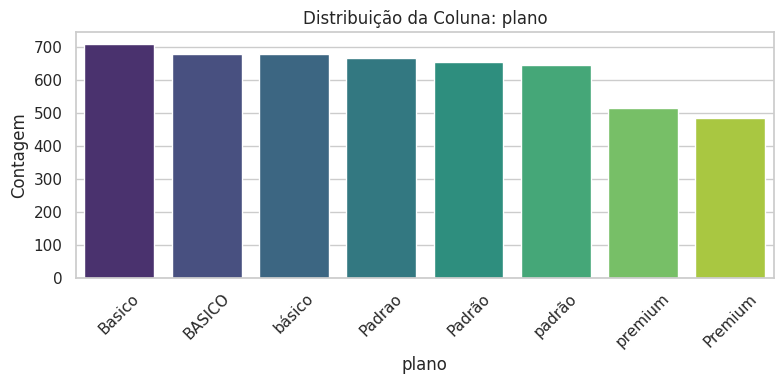


=== Análise da Coluna: ciclo ===


,Frequência Absoluta
ciclo,
Mensal,3794
Anual,1231


/tmp/ipykernel_1134/743954737.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=contagem.index, palette='viridis')


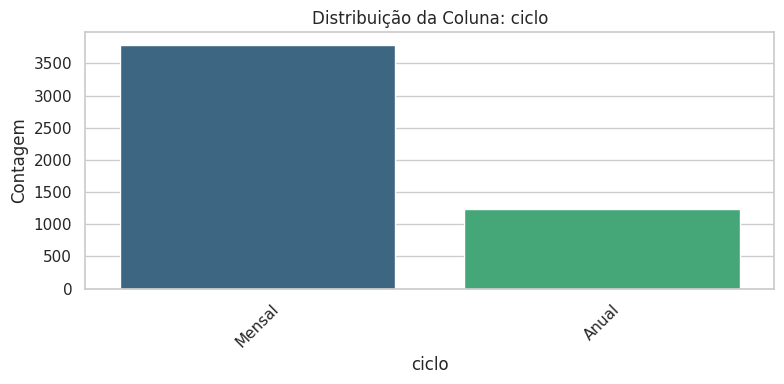


=== Análise da Coluna: regiao ===


,Frequência Absoluta
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-Oeste,488
Norte,408
?,170


/tmp/ipykernel_1134/743954737.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=contagem.index, palette='viridis')


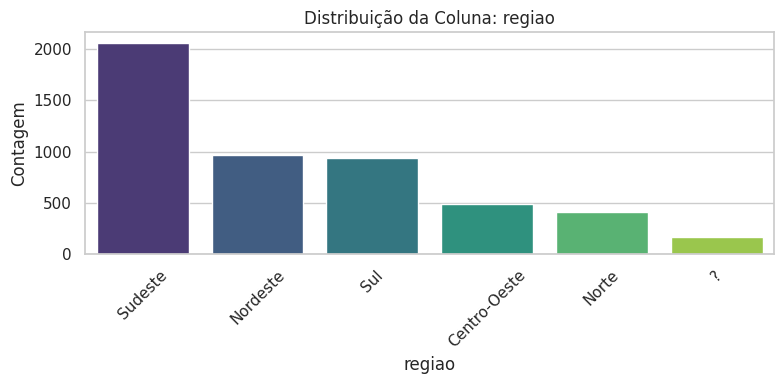


=== Análise da Coluna: canal_aquisicao ===


,Frequência Absoluta
canal_aquisicao,
Organico,781
orgânico,729
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


/tmp/ipykernel_1134/743954737.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=contagem.index, palette='viridis')


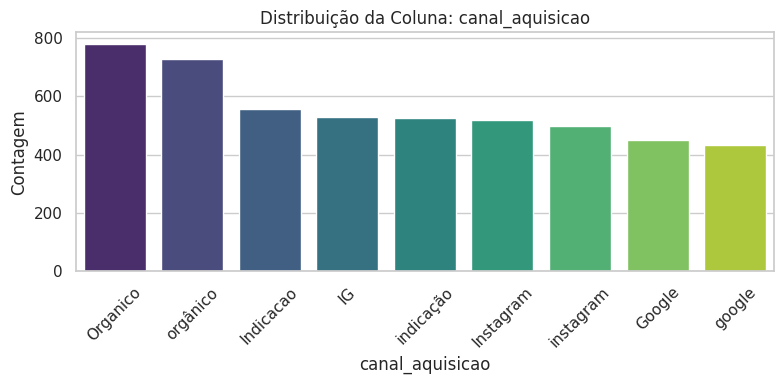

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista das colunas desejadas
colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configuração do estilo dos gráficos
sns.set_theme(style="whitegrid")

for col in colunas_analise:
    if col in df.columns:
        print(f"\n=== Análise da Coluna: {col} ===")

        # Contagem de valores únicos
        contagem = df[col].value_counts(dropna=False)
        display(contagem.to_frame(name='Frequência Absoluta'))

        # Plotagem do gráfico de barras
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col, order=contagem.index, palette='viridis')
        plt.title(f'Distribuição da Coluna: {col}')
        plt.xlabel(col)
        plt.ylabel('Contagem')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print(f"\nA coluna '{col}' não foi encontrada no DataFrame.")

### Passo 4: Limpeza, Padronização e Análise de Nulos
Nesta etapa iremos:
1. Identificar a quantidade de valores nulos por coluna.
2. Filtrar o DataFrame para analisar registros com região indeterminada (`?`).
3. Tratar e padronizar as colunas `plano` e `canal_aquisicao` mapeando textos equivalentes.

In [32]:
# 1. Contagem de valores nulos por coluna
print("=== Quantidade de Nulos por Coluna ===")
nulos_por_coluna = df.isnull().sum()
display(nulos_por_coluna.to_frame(name='Total de Nulos'))

=== Quantidade de Nulos por Coluna ===


,Total de Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [33]:
# 2. Exemplo de DataFrame onde a coluna regiao é '?'
print("=== Amostra de linhas onde 'regiao' é '?' ===")
df_regiao_interrogacao = df[df['regiao'] == '?']
display(df_regiao_interrogacao.head())

=== Amostra de linhas onde 'regiao' é '?' ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


In [34]:
# 3. Padronização da coluna 'plano'
mapeamento_plano = {
    'Basico': 'básico',
    'BASICO': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])

# 4. Padronização da coluna 'canal_aquisicao'
mapeamento_canal = {
    'Organico': 'orgânico',
    'orgânico': 'orgânico',
    'Indicacao': 'indicação',
    'indicação': 'indicação',
    'Instagram': 'instagram',
    'instagram': 'instagram',
    'IG': 'instagram',
    'Google': 'google',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapeamento_canal).fillna(df['canal_aquisicao'])

# Verificação após a limpeza
print("=== Valores únicos após a padronização ===")
print("\nPlano:")
display(df['plano'].value_counts(dropna=False).to_frame())

print("\nCanal de Aquisição:")
display(df['canal_aquisicao'].value_counts(dropna=False).to_frame())

=== Valores únicos após a padronização ===

Plano:


,count
plano,
básico,2062
padrão,1965
premium,998



Canal de Aquisição:


,count
canal_aquisicao,
instagram,1547
orgânico,1510
indicação,1082
google,886


### Passo 5: Substituir '?' por Nulo
Vamos substituir todas as interrogações (`?`) presentes no DataFrame por valores nulos (`NaN`) do pandas.

In [35]:
import numpy as np

# Substitui todos os caracteres '?' por NaN
df = df.replace('?', np.nan)

# Exibe a quantidade atualizada de nulos por coluna
print("=== Nova Quantidade de Nulos por Coluna ===")
display(df.isnull().sum().to_frame(name='Total de Nulos'))

=== Nova Quantidade de Nulos por Coluna ===


,Total de Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [8]:
df

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,1789,21,padrão,Mensal,34.9,Nordeste,indicação,8,2022-11-22,NaN,2024-01-12,2024-01-31,13,424.9,NaN,0
5021,1968,42,padrão,Mensal,34.9,Sudeste,indicação,6,2021-07-26,NaN,2024-01-07,2024-01-31,15,900.0,NaN,0
5022,2667,66,padrão,Mensal,34.9,Sudeste,orgânico,9,2023-05-26,NaN,2024-01-25,2024-01-31,14,232.2,NaN,0
5023,4321,39,básico,Mensal,19.9,Sudeste,indicação,7,2022-12-16,NaN,2024-01-04,2024-01-31,16,448.2,NaN,0


### Passo 6: Converter colunas de data para o tipo Datetime
Vamos identificar as colunas que começam com `data_` (ou especificá-las) e convertê-las para o tipo de dados `datetime`.

In [36]:
# Identifica as colunas de data no dataset
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

for col in colunas_data:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# Exibe os novos tipos das colunas para conferência
print("=== Tipos de Coluna Atualizados ===")
display(df[colunas_data].dtypes.to_frame(name='Tipo de Dado'))

=== Tipos de Coluna Atualizados ===


,Tipo de Dado
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]
data_ultimo_acesso,datetime64[ns]
data_extracao,datetime64[ns]


### Passo 7: Calcular as Diferenças entre Datas
Vamos computar a diferença em dias entre as colunas de data e adicioná-las como novas colunas de análise no DataFrame.

In [37]:
# 1. Diferença em dias entre assinatura e cancelamento (para clientes que deram churn)
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Diferença em dias entre assinatura e a data de extração (tempo total de vida do cliente)
df['dias_desde_assinatura_ate_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# 3. Diferença em dias entre o último acesso e a data de extração
df['dias_desde_ultimo_acesso_ate_extracao'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# Exibindo os primeiros registros com as novas colunas adicionadas
colunas_novas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao',
                 'dias_assinatura_ate_cancelamento', 'dias_desde_assinatura_ate_extracao', 'dias_desde_ultimo_acesso_ate_extracao']

display(df[colunas_novas].head())

,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao
0,2023-04-11,NaT,2024-01-29,2024-01-31,NaN,295,2.0
1,2022-06-02,NaT,2024-01-30,2024-01-31,NaN,608,1.0
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,1047,457.0
3,2023-04-02,NaT,2024-01-13,2024-01-31,NaN,304,18.0
4,2023-04-21,NaT,2024-01-16,2024-01-31,NaN,285,15.0


### Passo 8: Sanity Check nas Colunas de Diferença de Datas
Vamos validar se as diferenças calculadas fazem sentido lógico:
1. Não devem existir durações negativas (ex: data de cancelamento anterior à data de assinatura).
2. Exibir estatísticas gerais de cada coluna criada.

In [38]:
colunas_diferenca = [
    'dias_assinatura_ate_cancelamento',
    'dias_desde_assinatura_ate_extracao',
    'dias_desde_ultimo_acesso_ate_extracao'
]

print("=== 1. Verificação de Inconsistências (Valores Negativos) ===")
for col in colunas_diferenca:
    negativos = (df[col] < 0).sum()
    print(f"Coluna '{col}': {negativos} registros com valores negativos (inconsistentes)")

print("\n=== 2. Estatísticas Descritivas das Diferenças ===")
display(df[colunas_diferenca].describe())

=== 1. Verificação de Inconsistências (Valores Negativos) ===
Coluna 'dias_assinatura_ate_cancelamento': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_desde_assinatura_ate_extracao': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_desde_ultimo_acesso_ate_extracao': 0 registros com valores negativos (inconsistentes)

=== 2. Estatísticas Descritivas das Diferenças ===


,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao
count,1516.000000,5025.000000,4975.000000
mean,220.407652,412.432040,40.451859
std,145.004268,270.382969,55.107192
min,11.000000,1.000000,0.000000
25%,118.000000,213.000000,10.000000
50%,182.500000,349.000000,20.000000
75%,288.500000,549.000000,44.000000
max,1067.000000,1815.000000,469.000000


### Passo 9: Adicionar a Diferença entre Último Acesso e Cancelamento
Vamos calcular quantos dias se passaram entre a data do último acesso e a data de cancelamento efetivo para os clientes que cancelaram o serviço.

In [39]:
# Calcula a diferença entre a data de cancelamento e a data do último acesso
df['dias_ultimo_acesso_ate_cancelamento'] = (df['data_cancelamento'] - df['data_ultimo_acesso']).dt.days

# Exibe os dados e estatísticas para validar a nova coluna
print("=== Amostra com a Nova Diferença ===")
display(df[['data_ultimo_acesso', 'data_cancelamento', 'dias_ultimo_acesso_ate_cancelamento']].dropna().head())

print("\n=== Sanity Check da Nova Coluna (Valores Negativos) ===")
negativos = (df['dias_ultimo_acesso_ate_cancelamento'] < 0).sum()
print(f"Registros com valores negativos: {negativos}")

=== Amostra com a Nova Diferença ===


,data_ultimo_acesso,data_cancelamento,dias_ultimo_acesso_ate_cancelamento
2,2022-10-31,2022-11-17,17.0
6,2023-12-09,2023-12-28,19.0
8,2023-12-07,2023-12-17,10.0
11,2023-07-02,2023-11-16,137.0
17,2023-03-29,2023-04-15,17.0



=== Sanity Check da Nova Coluna (Valores Negativos) ===
Registros com valores negativos: 0


### Passo 10: Revisão Completa e Criação de Todas as Colunas de Diferença de Datas
Vamos garantir que todas as possíveis diferenças cronológicas lógicas entre as colunas de data sejam calculadas e validadas conjuntamente:

1. `dias_assinatura_ate_cancelamento`: Tempo ativo até o cancelamento (para clientes que deram churn).
2. `dias_desde_assinatura_ate_extracao`: Tempo total de vida desde a adesão até a extração dos dados.
3. `dias_desde_ultimo_acesso_ate_extracao`: Dias de inatividade até a extração.
4. `dias_ultimo_acesso_ate_cancelamento`: Distância entre o último acesso e o cancelamento.
5. `dias_assinatura_ate_ultimo_acesso`: Tempo total decorrido entre o início do contrato e o último acesso do usuário (Métrica adicionada agora).

In [40]:
# 1. Diferença entre assinatura e cancelamento
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Diferença entre assinatura e data de extração
df['dias_desde_assinatura_ate_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# 3. Diferença entre o último acesso e a data de extração
df['dias_desde_ultimo_acesso_ate_extracao'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 4. Diferença entre último acesso e cancelamento
df['dias_ultimo_acesso_ate_cancelamento'] = (df['data_cancelamento'] - df['data_ultimo_acesso']).dt.days

# 5. [Nova] Diferença entre assinatura e último acesso
df['dias_assinatura_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# Lista de todas as colunas de diferenças geradas
todas_diferencas = [
    'dias_assinatura_ate_cancelamento',
    'dias_desde_assinatura_ate_extracao',
    'dias_desde_ultimo_acesso_ate_extracao',
    'dias_ultimo_acesso_ate_cancelamento',
    'dias_assinatura_ate_ultimo_acesso'
]

# --- SANITY CHECK UNIFICADO ---
print("=== 1. Detecção de Inconsistências Cronológicas (Valores Negativos) ===")
for col in todas_diferencas:
    negativos = (df[col] < 0).sum()
    print(f"Coluna '{col}': {negativos} registros com valores negativos (inconsistentes)")

print("\n=== 2. Estatísticas Descritivas Gerais das Diferenças ===")
display(df[todas_diferencas].describe())

print("\n=== 3. Visualização de Amostra das Colunas de Datas e Diferenças ===")
display(df[['data_assinatura', 'data_ultimo_acesso', 'data_cancelamento', 'data_extracao'] + todas_diferencas].head())

=== 1. Detecção de Inconsistências Cronológicas (Valores Negativos) ===
Coluna 'dias_assinatura_ate_cancelamento': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_desde_assinatura_ate_extracao': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_desde_ultimo_acesso_ate_extracao': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_ultimo_acesso_ate_cancelamento': 0 registros com valores negativos (inconsistentes)
Coluna 'dias_assinatura_ate_ultimo_acesso': 1 registros com valores negativos (inconsistentes)

=== 2. Estatísticas Descritivas Gerais das Diferenças ===


,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso
count,1516.000000,5025.000000,4975.000000,1501.000000,4975.000000
mean,220.407652,412.432040,40.451859,21.000666,372.186533
std,145.004268,270.382969,55.107192,10.783104,277.107592
min,11.000000,1.000000,0.000000,3.000000,-47.000000
25%,118.000000,213.000000,10.000000,12.000000,163.000000
50%,182.500000,349.000000,20.000000,21.000000,307.000000
75%,288.500000,549.000000,44.000000,30.000000,512.000000
max,1067.000000,1815.000000,469.000000,137.000000,1809.000000



=== 3. Visualização de Amostra das Colunas de Datas e Diferenças ===


,data_assinatura,data_ultimo_acesso,data_cancelamento,data_extracao,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso
0,2023-04-11,2024-01-29,NaT,2024-01-31,NaN,295,2.0,NaN,293.0
1,2022-06-02,2024-01-30,NaT,2024-01-31,NaN,608,1.0,NaN,607.0
2,2021-03-20,2022-10-31,2022-11-17,2024-01-31,607.0,1047,457.0,17.0,590.0
3,2023-04-02,2024-01-13,NaT,2024-01-31,NaN,304,18.0,NaN,286.0
4,2023-04-21,2024-01-16,NaT,2024-01-31,NaN,285,15.0,NaN,270.0


### Passo 11: Análise Detalhada das Colunas Numéricas
Vamos identificar de forma automática todas as colunas numéricas do DataFrame, extrair suas estatísticas descritivas completas e mapear a quantidade de valores nulos existentes em cada uma.

In [41]:
import pandas as pd

# 1. Identificar colunas numéricas (tipos int e float)
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("=== Colunas Numéricas Identificadas ===")
print(colunas_numericas)

# 2. Contar valores nulos especificamente para as colunas numéricas
print("\n=== Quantidade de Valores Nulos nas Colunas Numéricas ===")
nulos_numericas = df[colunas_numericas].isnull().sum().to_frame(name='Total de Nulos')
nulos_numericas['% de Nulos'] = (df[colunas_numericas].isnull().mean() * 100).round(2)
display(nulos_numericas)

# 3. Estatísticas descritivas gerais destas colunas
print("\n=== Estatísticas Descritivas das Colunas Numéricas ===")
display(df[colunas_numericas].describe())

=== Colunas Numéricas Identificadas ===
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dias_assinatura_ate_cancelamento', 'dias_desde_assinatura_ate_extracao', 'dias_desde_ultimo_acesso_ate_extracao', 'dias_ultimo_acesso_ate_cancelamento', 'dias_assinatura_ate_ultimo_acesso']

=== Quantidade de Valores Nulos nas Colunas Numéricas ===


,Total de Nulos,% de Nulos
cliente_id,0,0.00
idade,0,0.00
valor_mensal,0,0.00
nps,0,0.00
dias_ativos_ult_mes,0,0.00
horas_assistidas_total,0,0.00
churn,0,0.00
dias_assinatura_ate_cancelamento,3509,69.83
dias_desde_assinatura_ate_extracao,0,0.00
dias_desde_ultimo_acesso_ate_extracao,50,1.00



=== Estatísticas Descritivas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,5025.000000,4975.000000,1501.000000,4975.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,412.432040,40.451859,21.000666,372.186533
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,270.382969,55.107192,10.783104,277.107592
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,1.000000,0.000000,3.000000,-47.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,213.000000,10.000000,12.000000,163.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,349.000000,20.000000,21.000000,307.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,549.000000,44.000000,30.000000,512.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,1815.000000,469.000000,137.000000,1809.000000


In [15]:
df.isnull


<bound method DataFrame.isnull of       cliente_id  idade    plano   ciclo  valor_mensal    regiao  \
0           5746     36   básico   Anual          19.9   Sudeste   
1           4100     48   padrão  Mensal          34.9   Sudeste   
2           4690     48  premium  Mensal          55.9  Nordeste   
3           3454     46   básico   Anual        1990.0       Sul   
4           1437     46   básico  Mensal          19.9     Norte   
...          ...    ...      ...     ...           ...       ...   
5020        1789     21   padrão  Mensal          34.9  Nordeste   
5021        1968     42   padrão  Mensal          34.9   Sudeste   
5022        2667     66   padrão  Mensal          34.9   Sudeste   
5023        4321     39   básico  Mensal          19.9   Sudeste   
5024        2688     48   básico  Mensal          19.9  Nordeste   

     canal_aquisicao  nps data_assinatura data_cancelamento  ...  \
0          indicação    6      2023-04-11               NaT  ...   
1           orgânico    8      2022-06-02               NaT  ...   
2           orgânico    4      2021-03-20        2022-11-17  ...   
3             google   10      2023-04-02               NaT  ...   
4          indicação    8      2023-04-21               NaT  ...   
...              ...  ...             ...               ...  ...   
5020       indicação    8      2022-11-22               NaT  ...   
5021       indicação    6      2021-07-26               NaT  ...   
5022        orgânico    9      2023-05-26               NaT  ...   
5023       indicação    7      2022-12-16               NaT  ...   
5024        orgânico    5      2023-06-17        2023-11-19  ...   

     data_extracao dias_ativos_ult_mes  horas_assistidas_total  \
0       2024-01-31                  15                   276.0   
1       2024-01-31                  14                   394.9   
2       2024-01-31                   5                   257.0   
3       2024-01-31                  19                   385.0   
4       2024-01-31                  11                   205.3   
...            ...                 ...                     ...   
5020    2024-01-31                  13                   424.9   
5021    2024-01-31                  15                   900.0   
5022    2024-01-31                  14                   232.2   
5023    2024-01-31                  16                   448.2   
5024    2024-01-31                   0                     0.0   

      motivo_cancelamento churn  dias_assinatura_ate_cancelamento  \
0                     NaN     0                               NaN   
1                     NaN     0                               NaN   
2                   PREÇO     1                             607.0   
3                     NaN     0                               NaN   
4                     NaN     0                               NaN   
...                   ...   ...                               ...   
5020                  NaN     0                               NaN   
5021                  NaN     0                               NaN   
5022                  NaN     0                               NaN   
5023                  NaN     0                               NaN   
5024  Pouco conteúdo novo     1                             155.0   

      dias_desde_assinatura_ate_extracao  \
0                                    295   
1                                    608   
2                                   1047   
3                                    304   
4                                    285   
...                                  ...   
5020                                 435   
5021                                 919   
5022                                 250   
5023                                 411   
5024                                 228   

      dias_desde_ultimo_acesso_ate_extracao  \
0                                       2.0   
1                                       1.0   
2                                     45

### Passo 12: Filtrar Dataset por Consistência Cronológica
Vamos filtrar o DataFrame de modo que a coluna `dias_assinatura_ate_ultimo_acesso` contenha apenas valores positivos, zero ou nulos (`NaN`), removendo inconsistências temporais.

In [42]:
# Quantidade de linhas antes do filtro
linhas_antes = len(df)

# Aplicando o filtro solicitado (valores >= 0 ou nulos)
filtro_consistente = (df['dias_assinatura_ate_ultimo_acesso'] >= 0) | (df['dias_assinatura_ate_ultimo_acesso'].isnull())
df = df[filtro_consistente]

# Quantidade de linhas após o filtro
linhas_depois = len(df)
linhas_removidas = linhas_antes - linhas_depois

print(f"=== Resultado da Filtragem ===")
print(f"Linhas antes do filtro: {linhas_antes}")
print(f"Linhas após o filtro: {linhas_depois}")
print(f"Linhas inconsistentes removidas: {linhas_removidas}")

# Sanity check rápido
negativos_restantes = (df['dias_assinatura_ate_ultimo_acesso'] < 0).sum()
print(f"Valores negativos restantes na coluna: {negativos_restantes}")

=== Resultado da Filtragem ===
Linhas antes do filtro: 5025
Linhas após o filtro: 5024
Linhas inconsistentes removidas: 1
Valores negativos restantes na coluna: 0


### Passo 13: Visualização das Variáveis Numéricas (Histogramas e Boxplots)
Para entender melhor a distribuição dos nossos dados numéricos e a presença de potenciais outliers, vamos gerar um histograma e um boxplot para cada coluna numérica identificada, exceto `cliente_id`.

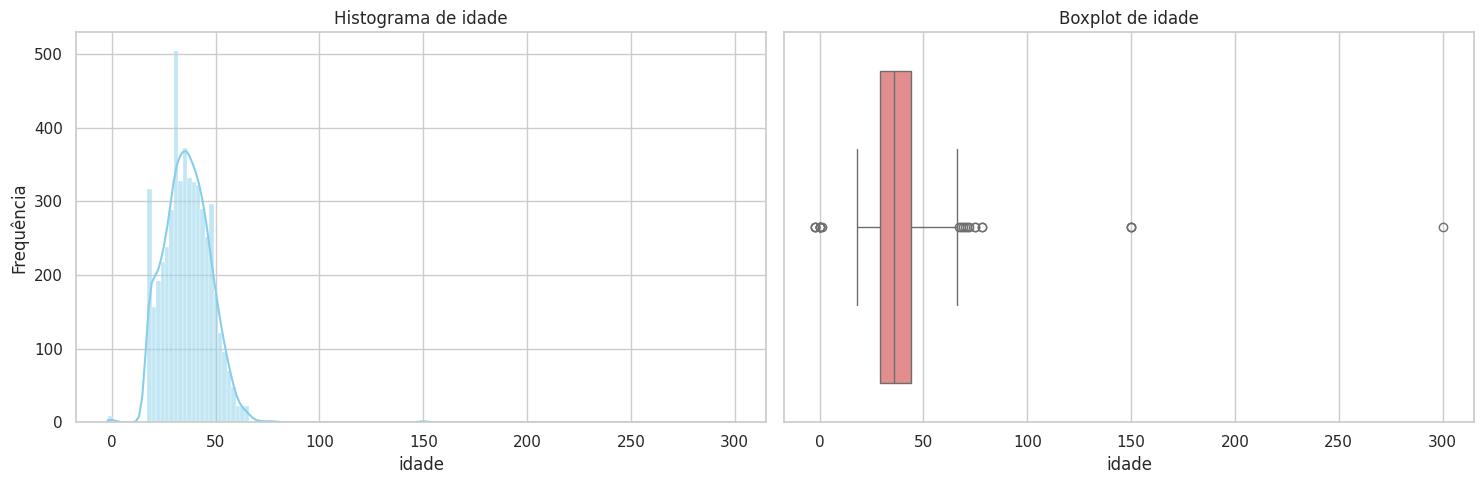

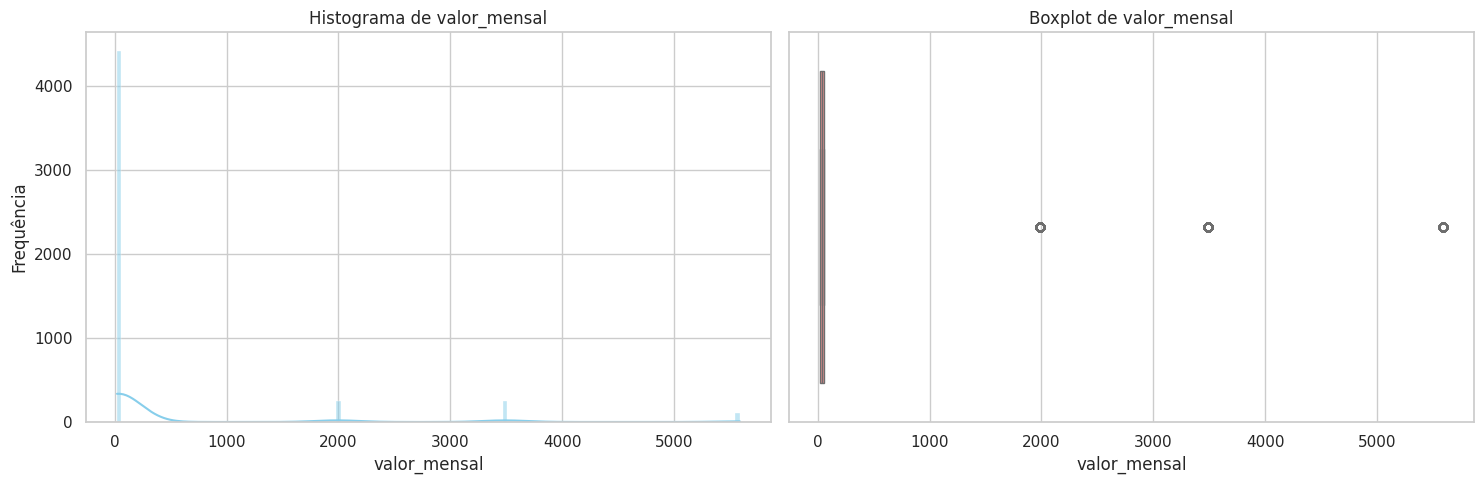

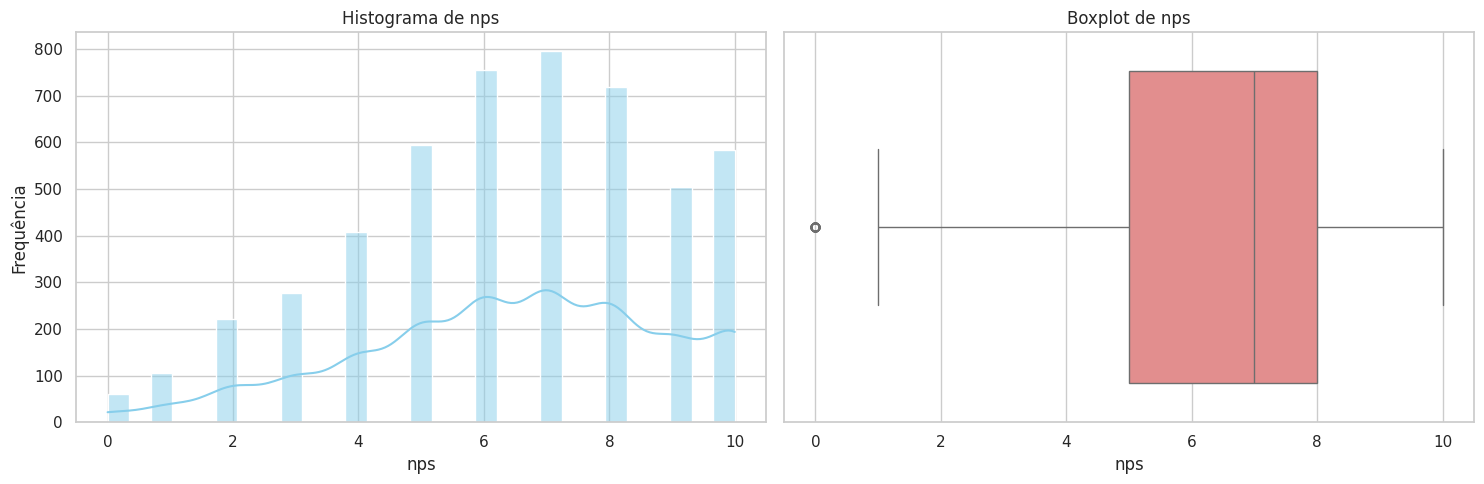

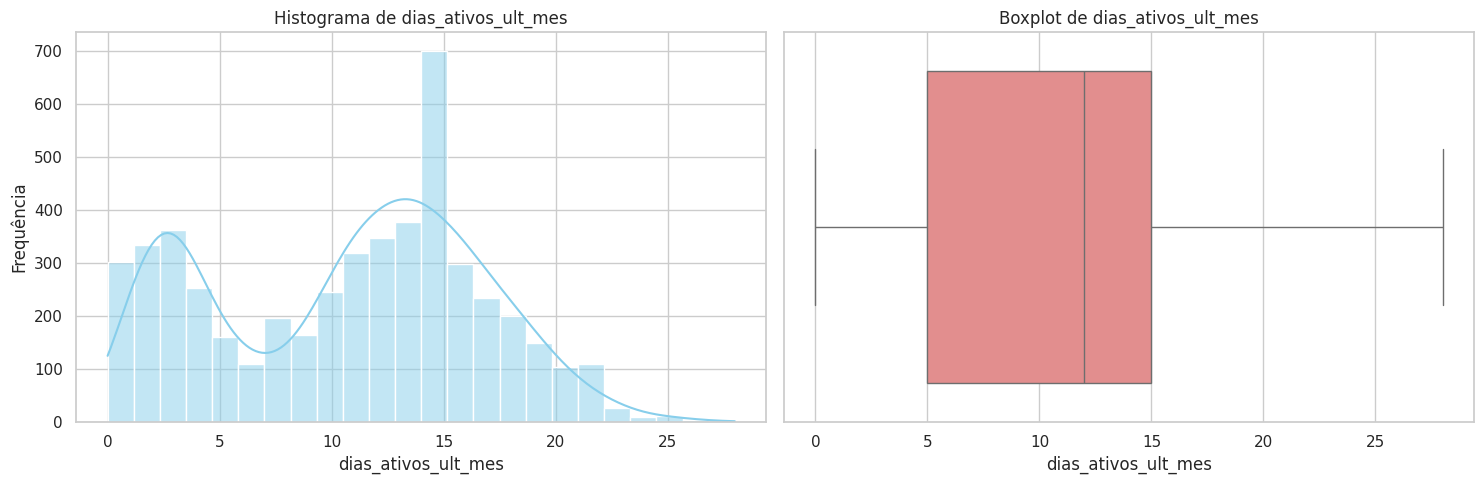

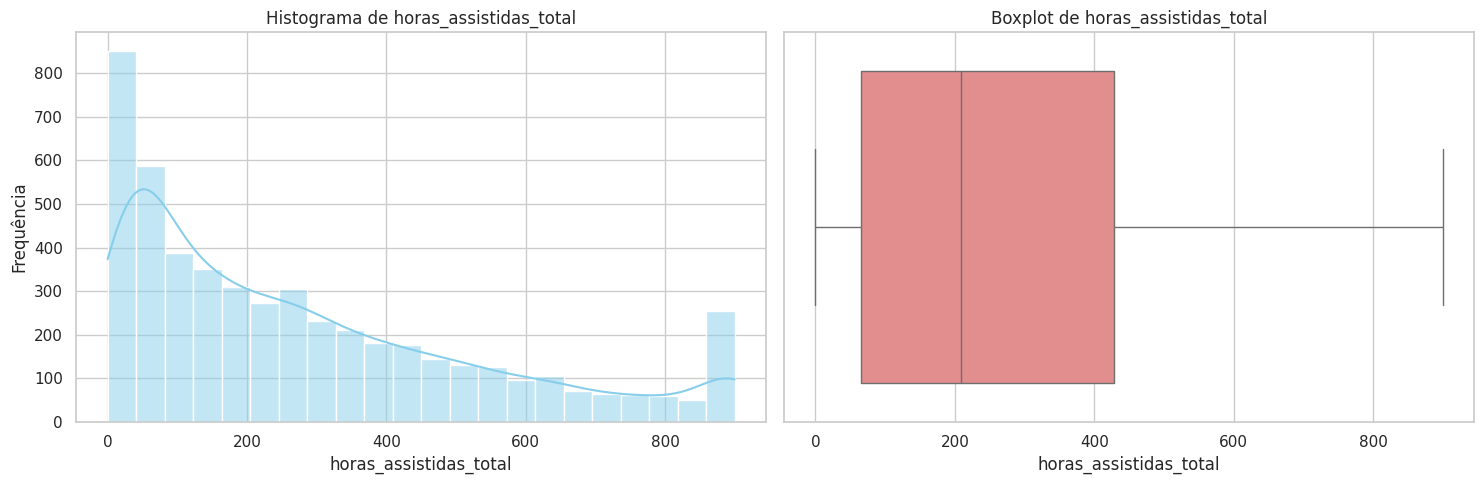

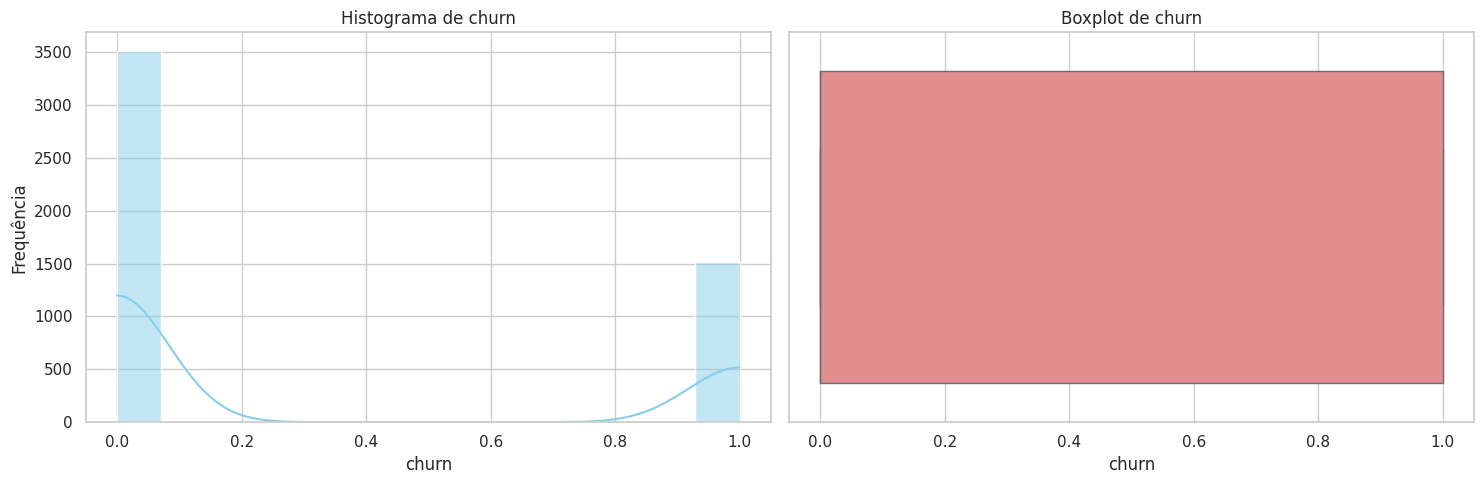

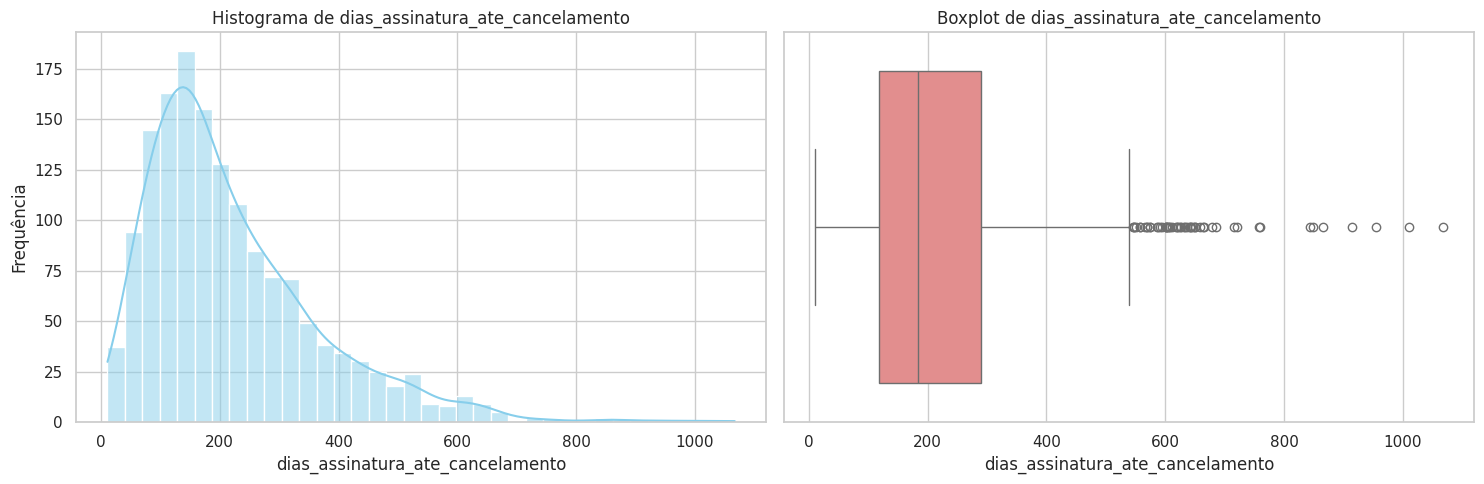

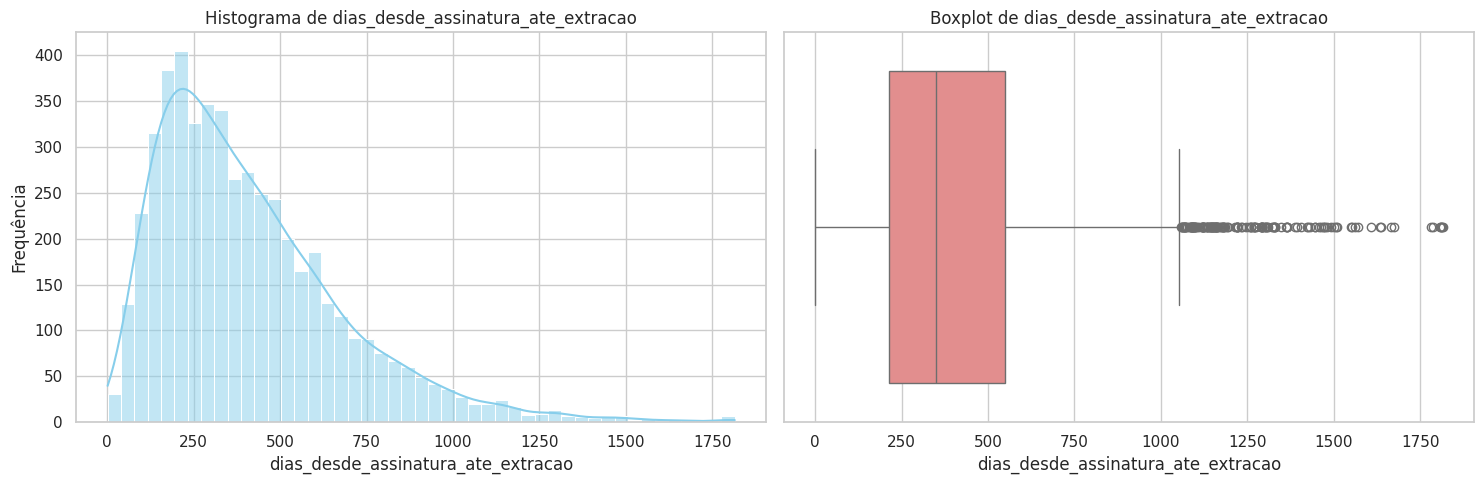

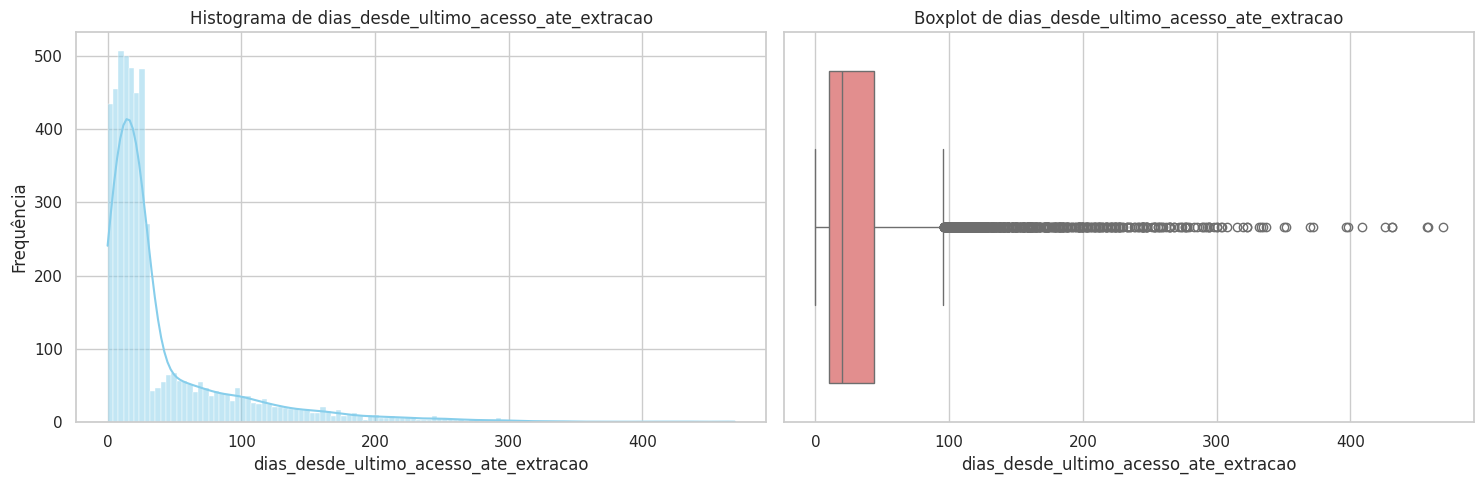

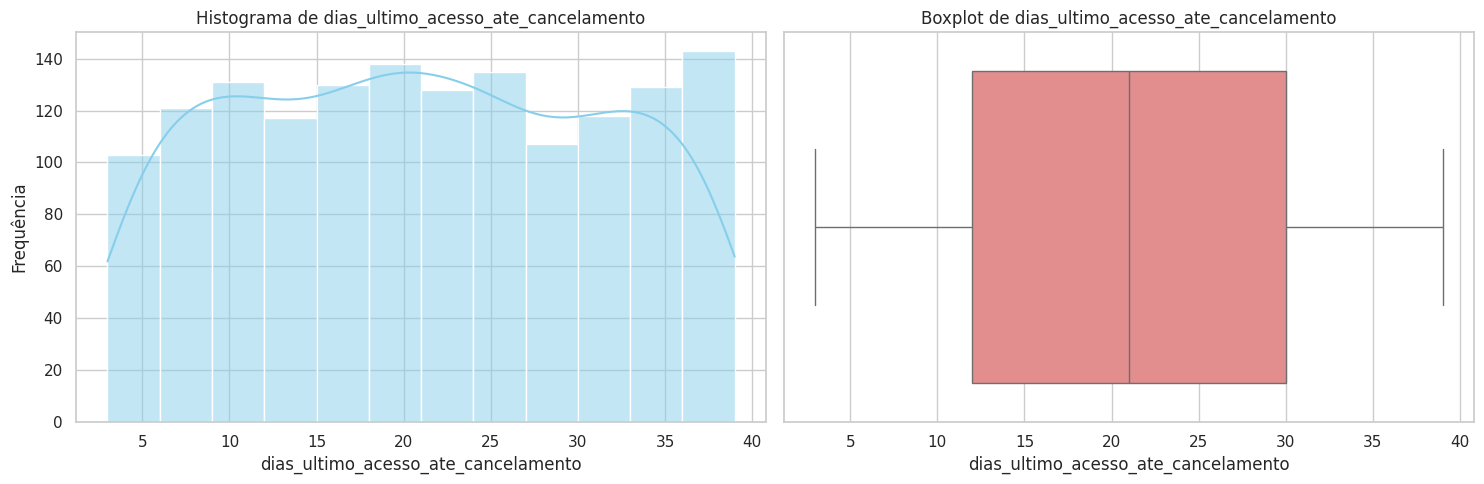

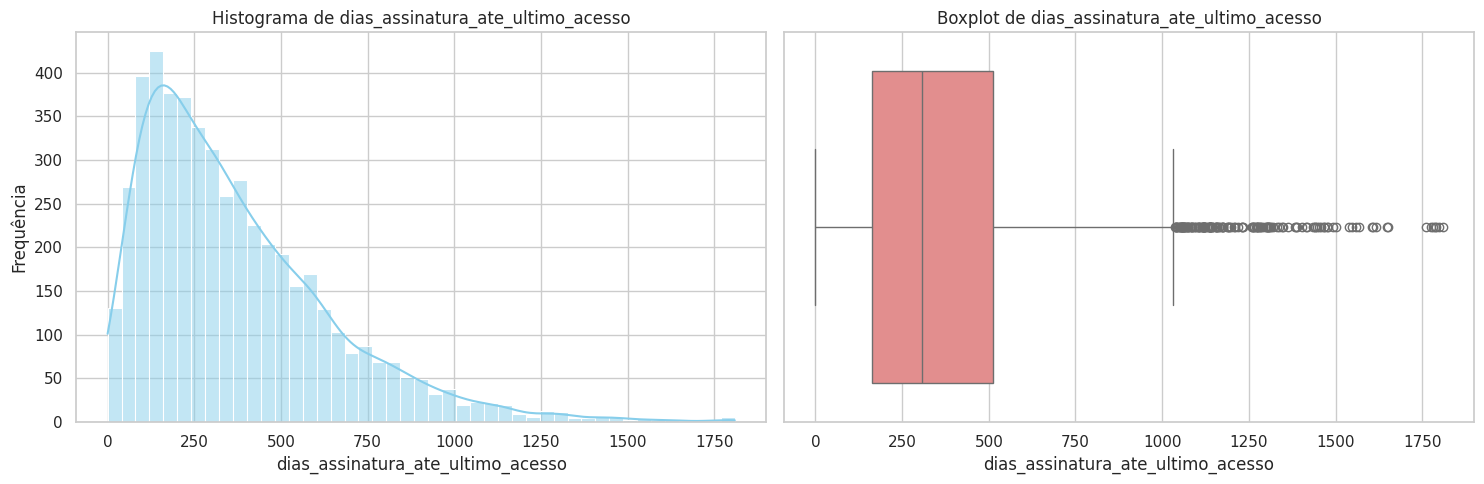

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas numéricas para plotar (excluindo cliente_id)
colunas_para_plotar = [col for col in colunas_numericas if col != 'cliente_id']

# Configuração geral do estilo do seaborn
sns.set_theme(style="whitegrid")

for col in colunas_para_plotar:
    # Criar uma figura com dois subplots lado a lado (1 linha, 2 colunas)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. Histograma
    sns.histplot(data=df, x=col, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')

    # 2. Boxplot
    sns.boxplot(data=df, x=col, ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)

    # Ajustar layout para não sobrepor textos
    plt.tight_layout()
    plt.show()

### Passo 14: Filtrar Dataset por Faixa Etária Válida
Para garantir a consistência das nossas análises, vamos remover registros onde a idade seja menor do que 18 anos ou maior do que 90 anos.

In [44]:
# Quantidade de linhas antes do filtro de idade
linhas_antes_idade = len(df)

# Filtrando para manter apenas idades entre 18 e 90 anos (inclusive)
df = df[(df['idade'] >= 18) & (df['idade'] <= 90)]

# Quantidade de linhas após o filtro de idade
linhas_depois_idade = len(df)
linhas_removidas_idade = linhas_antes_idade - linhas_depois_idade

print("=== Resultado do Filtro de Idade ===")
print(f"Linhas antes do filtro: {linhas_antes_idade}")
print(f"Linhas após o filtro: {linhas_depois_idade}")
print(f"Clientes removidos (Idade < 18 ou > 90): {linhas_removidas_idade}")

# Exibir a nova distribuição resumida da coluna idade
print("\n=== Nova Amplitude de Idade ===")
print(f"Idade Mínima: {df['idade'].min()}")
print(f"Idade Máxima: {df['idade'].max()}")

=== Resultado do Filtro de Idade ===
Linhas antes do filtro: 5024
Linhas após o filtro: 5011
Clientes removidos (Idade < 18 ou > 90): 13

=== Nova Amplitude de Idade ===
Idade Mínima: 18
Idade Máxima: 78


In [19]:
df

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,2024-01-31,15,276.0,NaN,0,NaN,295,2.0,NaN,293.0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,2024-01-31,14,394.9,NaN,0,NaN,608,1.0,NaN,607.0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,2024-01-31,5,257.0,PREÇO,1,607.0,1047,457.0,17.0,590.0
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,2024-01-31,19,385.0,NaN,0,NaN,304,18.0,NaN,286.0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,2024-01-31,11,205.3,NaN,0,NaN,285,15.0,NaN,270.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,1789,21,padrão,Mensal,34.9,Nordeste,indicação,8,2022-11-22,NaT,...,2024-01-31,13,424.9,NaN,0,NaN,435,19.0,NaN,416.0
5021,1968,42,padrão,Mensal,34.9,Sudeste,indicação,6,2021-07-26,NaT,...,2024-01-31,15,900.0,NaN,0,NaN,919,24.0,NaN,895.0
5022,2667,66,padrão,Mensal,34.9,Sudeste,orgânico,9,2023-05-26,NaT,...,2024-01-31,14,232.2,NaN,0,NaN,250,6.0,NaN,244.0
5023,4321,39,básico,Mensal,19.9,Sudeste,indicação,7,2022-12-16,NaT,...,2024-01-31,16,448.2,NaN,0,NaN,411,27.0,NaN,384.0


### Passo 15: Análise de Valores Mensais Atípicos
Vamos filtrar as linhas em que a coluna `valor_mensal` é maior que 1000 e analisar a distribuição dos valores distintos desta coluna no dataset.

In [45]:
# 1. Filtrar e exibir linhas onde valor_mensal é maior que 1000
print("=== Linhas com 'valor_mensal' superior a 1000 ===")
valores_maiores_1000 = df[df['valor_mensal'] > 1000]
display(valores_maiores_1000)

# 2. Contar e listar os valores distintos de 'valor_mensal' em todo o DataFrame
print("\n=== Contagem de Valores Distintos em 'valor_mensal' ===")
contagem_valores_mensais = df['valor_mensal'].value_counts(dropna=False).to_frame(name='Frequência')
display(contagem_valores_mensais)

print(f"\nTotal de valores distintos (incluindo nulos): {df['valor_mensal'].nunique(dropna=False)}")

=== Linhas com 'valor_mensal' superior a 1000 ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,2024-01-31,19,385.0,NaN,0,NaN,304,18.0,NaN,286.0
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,2024-01-31,15,160.7,NaN,0,NaN,193,4.0,NaN,189.0
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,...,2024-01-31,14,117.2,NaN,0,NaN,162,28.0,NaN,134.0
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,...,2024-01-31,11,180.4,NaN,0,NaN,292,9.0,NaN,283.0
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,2024-01-31,6,47.8,problema tecnico,1,75.0,122,67.0,20.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,2024-01-31,20,900.0,NaN,0,NaN,1156,18.0,NaN,1138.0
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,...,2024-01-31,18,900.0,NaN,0,NaN,1022,5.0,NaN,1017.0
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,2024-01-31,9,243.6,NaN,0,NaN,426,24.0,NaN,402.0
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,...,2024-01-31,11,160.6,NaN,0,NaN,273,22.0,NaN,251.0



=== Contagem de Valores Distintos em 'valor_mensal' ===


,Frequência
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104



Total de valores distintos (incluindo nulos): 6


### Passo 16: Ajustar Escala da Coluna `valor_mensal`
Para corrigir possíveis inconsistências de digitação ou escala, vamos dividir por 100 todos os valores da coluna `valor_mensal` que forem maiores do que 1900.

In [46]:
# Armazenar distribuição antes do ajuste para comparação
print("=== Distribuição de 'valor_mensal' ANTES do ajuste ===")
display(df['valor_mensal'].value_counts(dropna=False).to_frame(name='Antes'))

# Dividir por 100 os valores acima de 1900
df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] = df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] / 100

# Mostrar a distribuição após o ajuste
print("\n=== Distribuição de 'valor_mensal' DEPOIS do ajuste ===")
display(df['valor_mensal'].value_counts(dropna=False).to_frame(name='Depois'))

=== Distribuição de 'valor_mensal' ANTES do ajuste ===


,Antes
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104



=== Distribuição de 'valor_mensal' DEPOIS do ajuste ===


,Depois
valor_mensal,
19.9,2058
34.9,1958
55.9,995


### Passo 17: Engenharia de Recursos (Criação de Variáveis de Recência e Receita)
Vamos adicionar as três novas métricas solicitadas para enriquecer nossa análise de comportamento e receita dos clientes:
* `recencia`
* `meses_assinatura`
* `receita_acumulada`

In [47]:
import numpy as np

# 1) Criar variável 'recencia'
df['recencia'] = df['dias_desde_ultimo_acesso_ate_extracao']

# 2) Criar variável 'meses_assinatura' usando condicional lógica
# Nota: (data_extracao - data_assinatura) já foi calculado em dias como 'dias_desde_assinatura_ate_extracao'
condicao_ativo = df['data_cancelamento'].isnull()

df['meses_assinatura'] = np.where(
    condicao_ativo,
    df['dias_desde_assinatura_ate_extracao'] / 30.0,
    df['dias_assinatura_ate_cancelamento'] / 30.0
)

# 3) Criar variável 'receita_acumulada'
df['receita_acumulada'] = df['valor_mensal'] * df['meses_assinatura']

# Exibir estatísticas descritivas das novas variáveis geradas
print("=== Estatísticas Descritivas das Novas Colunas ===")
display(df[['recencia', 'meses_assinatura', 'receita_acumulada']].describe())

# Visualizar amostra dos dados para validar os cálculos
print("\n=== Amostra das Novas Colunas Criadas ===")
display(df[['cliente_id', 'valor_mensal', 'data_assinatura', 'data_cancelamento', 'data_extracao', 'recencia', 'meses_assinatura', 'receita_acumulada']].head(10))

=== Estatísticas Descritivas das Novas Colunas ===


,recencia,meses_assinatura,receita_acumulada
count,4961.000000,5011.000000,5011.000000
mean,40.452731,12.950376,428.914295
std,55.112223,9.186362,371.527653
min,0.000000,0.033333,0.663333
25%,10.000000,6.033333,168.585000
50%,20.000000,10.766667,321.080000
75%,44.000000,17.600000,570.033333
max,469.000000,60.500000,2893.756667



=== Amostra das Novas Colunas Criadas ===


,cliente_id,valor_mensal,data_assinatura,data_cancelamento,data_extracao,recencia,meses_assinatura,receita_acumulada
0,5746,19.9,2023-04-11,NaT,2024-01-31,2.0,9.833333,195.683333
1,4100,34.9,2022-06-02,NaT,2024-01-31,1.0,20.266667,707.306667
2,4690,55.9,2021-03-20,2022-11-17,2024-01-31,457.0,20.233333,1131.043333
3,3454,19.9,2023-04-02,NaT,2024-01-31,18.0,10.133333,201.653333
4,1437,19.9,2023-04-21,NaT,2024-01-31,15.0,9.500000,189.050000
5,1521,55.9,2022-11-22,NaT,2024-01-31,11.0,14.500000,810.550000
6,4918,19.9,2023-10-12,2023-12-28,2024-01-31,53.0,2.566667,51.076667
7,3842,34.9,2022-01-21,NaT,2024-01-31,19.0,24.666667,860.866667
8,1958,19.9,2023-04-26,2023-12-17,2024-01-31,55.0,7.833333,155.883333
9,3475,19.9,2023-10-07,NaT,2024-01-31,6.0,3.866667,76.946667


### Passo 18: Criar Novo DataFrame com Clientes Antigos
Vamos gerar o DataFrame `DF_novo` contendo apenas os clientes com tempo de assinatura ativo ou histórico (`dias_desde_assinatura_ate_extracao`) de no mínimo 220 dias.

In [48]:
# Criando o novo DataFrame com base na condição solicitada
DF_novo = df[df['dias_desde_assinatura_ate_extracao'] >= 220].copy()

# Exibindo informações sobre o novo DataFrame
print("=== Informações do DF_novo ===")
print(f"Quantidade total de linhas no DataFrame original: {len(df)}")
print(f"Quantidade total de linhas no DF_novo: {len(DF_novo)}")
print(f"Clientes filtrados (removidos por terem < 220 dias): {len(df) - len(DF_novo)}")

# Exibindo o intervalo da coluna de dias de assinatura no novo DataFrame para validação
print(f"\nIntervalo de dias no DF_novo: {DF_novo['dias_desde_assinatura_ate_extracao'].min()} a {DF_novo['dias_desde_assinatura_ate_extracao'].max()} dias")

# Amostra das primeiras linhas
print("\n=== Amostra das Primeiras Linhas de DF_novo ===")
display(DF_novo.head())

=== Informações do DF_novo ===
Quantidade total de linhas no DataFrame original: 5011
Quantidade total de linhas no DF_novo: 3668
Clientes filtrados (removidos por terem < 220 dias): 1343

Intervalo de dias no DF_novo: 220 a 1815 dias

=== Amostra das Primeiras Linhas de DF_novo ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_assinatura_ate_extracao,dias_desde_ultimo_acesso_ate_extracao,dias_ultimo_acesso_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,NaN,0,NaN,295,2.0,NaN,293.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,NaN,0,NaN,608,1.0,NaN,607.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,PREÇO,1,607.0,1047,457.0,17.0,590.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,NaN,0,NaN,304,18.0,NaN,286.0,18.0,10.133333,201.653333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,NaN,0,NaN,285,15.0,NaN,270.0,15.0,9.500000,189.050000


### Passo 19: Análise de Relação com o Churn (DataFrame `DF_novo`)

Nesta etapa, investigamos quais fatores comportamentais, demográficos e financeiros estão mais associados ao cancelamento (`churn = 1`) contra a retenção (`churn = 0`).

Definiremos primeiro as colunas numéricas e categóricas que serão avaliadas conforme solicitado.

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Definição das listas de variáveis solicitadas para análise
vars_numericas_churn = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes',
    'horas_assistidas_total', 'dias_assinatura_ate_ultimo_acesso',
    'dias_desde_assinatura_ate_extracao', 'recencia',
    'meses_assinatura', 'receita_acumulada'
]

vars_categoricas_churn = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

#### 19.1: Análise das Variáveis Numéricas vs Churn

Para cada variável numérica, geramos:
1. Um histograma de densidade sobreposto separando os grupos de churn por cor (azul para não churn, vermelho para churn).
2. Uma tabela de estatísticas descritivas segmentada por grupo.


==================== ANÁLISE DA VARIÁVEL: idade ====================


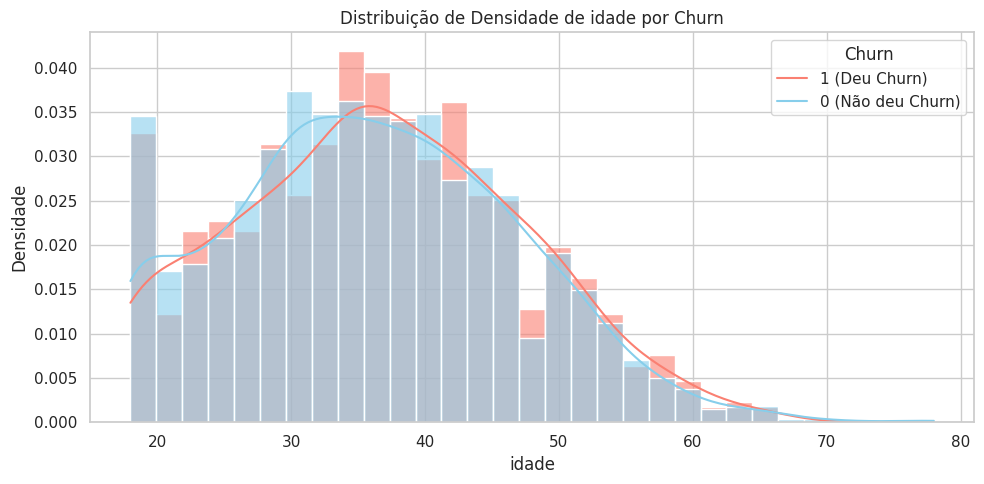

churn,0,1
count,2780.000000,888.000000
mean,36.125540,36.632883
std,10.633567,10.600266
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000



==================== ANÁLISE DA VARIÁVEL: valor_mensal ====================


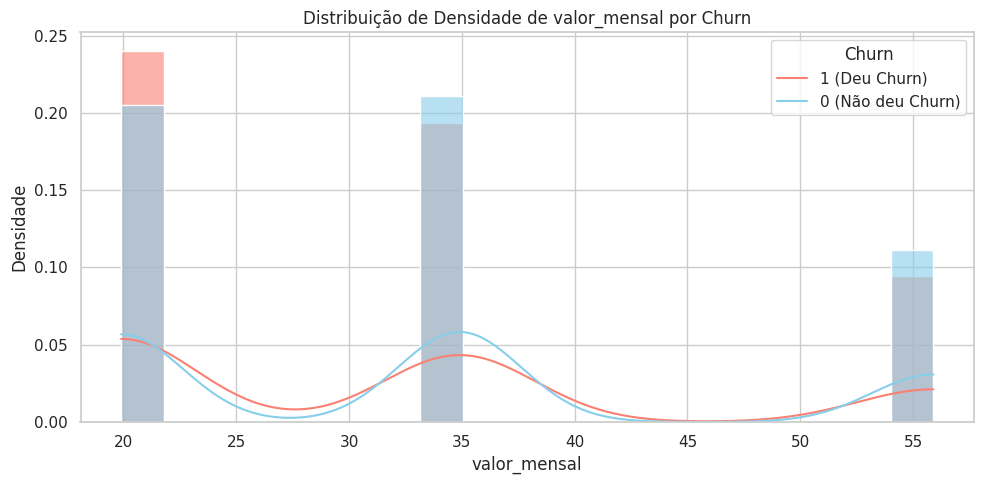

churn,0,1
count,2780.000000,888.000000
mean,33.496043,31.835811
std,13.370968,13.119920
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,34.900000,34.900000
max,55.900000,55.900000



==================== ANÁLISE DA VARIÁVEL: nps ====================


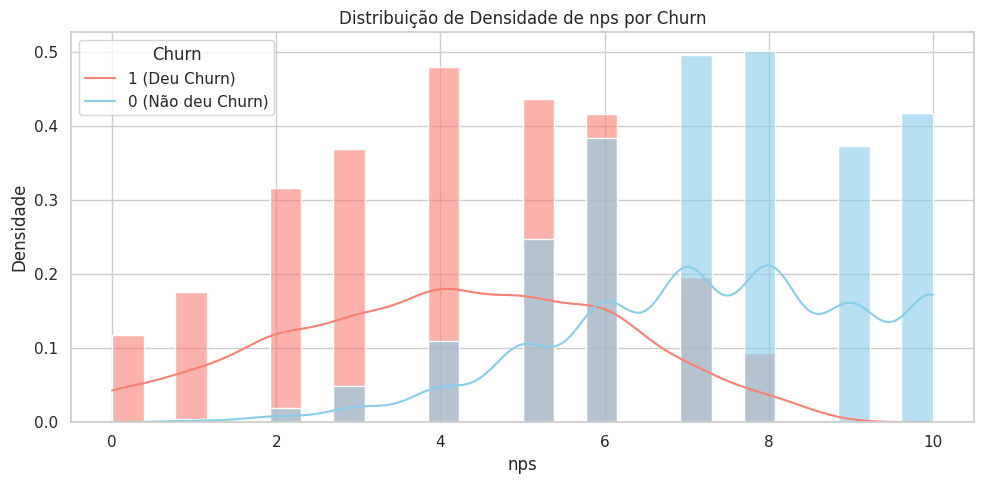

churn,0,1
count,2780.000000,888.000000
mean,7.376978,4.090090
std,1.877014,2.004165
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000



==================== ANÁLISE DA VARIÁVEL: dias_ativos_ult_mes ====================


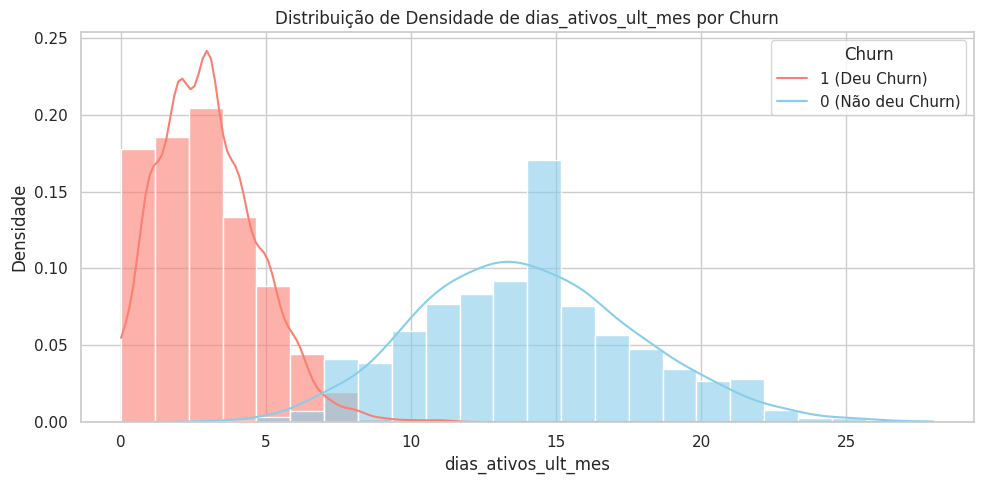

churn,0,1
count,2780.000000,888.000000
mean,13.995324,2.967342
std,3.755046,1.721950
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000



==================== ANÁLISE DA VARIÁVEL: horas_assistidas_total ====================


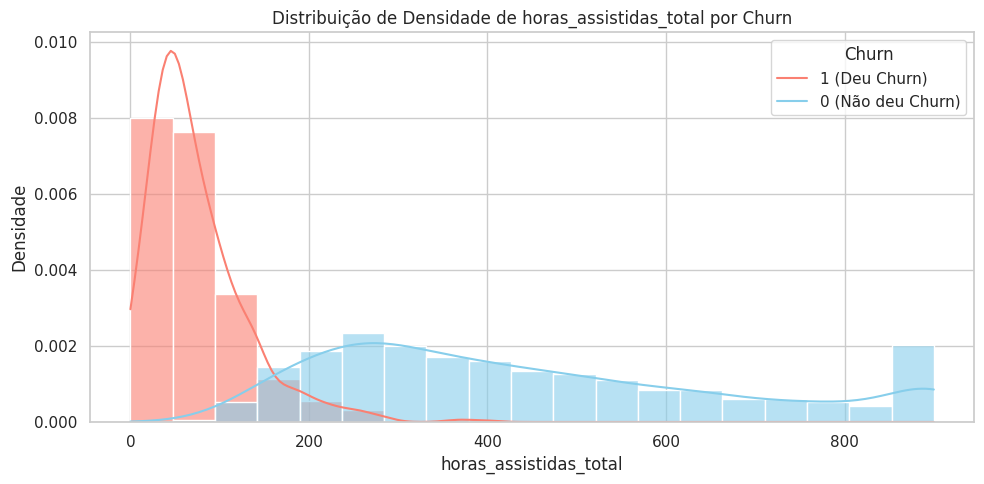

churn,0,1
count,2780.000000,888.000000
mean,448.891475,73.143131
std,226.739374,55.191559
min,73.900000,0.000000
25%,265.450000,35.925000
50%,395.600000,58.950000
75%,600.900000,96.600000
max,900.000000,400.000000



==================== ANÁLISE DA VARIÁVEL: dias_assinatura_ate_ultimo_acesso ====================


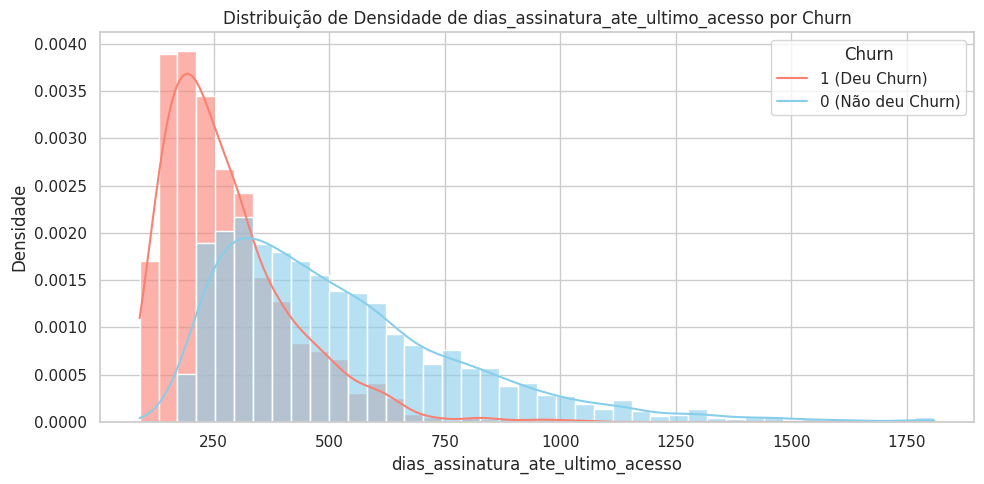

churn,0,1
count,2755.000000,878.000000
mean,528.301270,278.715262
std,266.179458,138.580418
min,192.000000,90.000000
25%,327.000000,176.000000
50%,465.000000,244.000000
75%,659.000000,342.500000
max,1809.000000,1040.000000



==================== ANÁLISE DA VARIÁVEL: dias_desde_assinatura_ate_extracao ====================


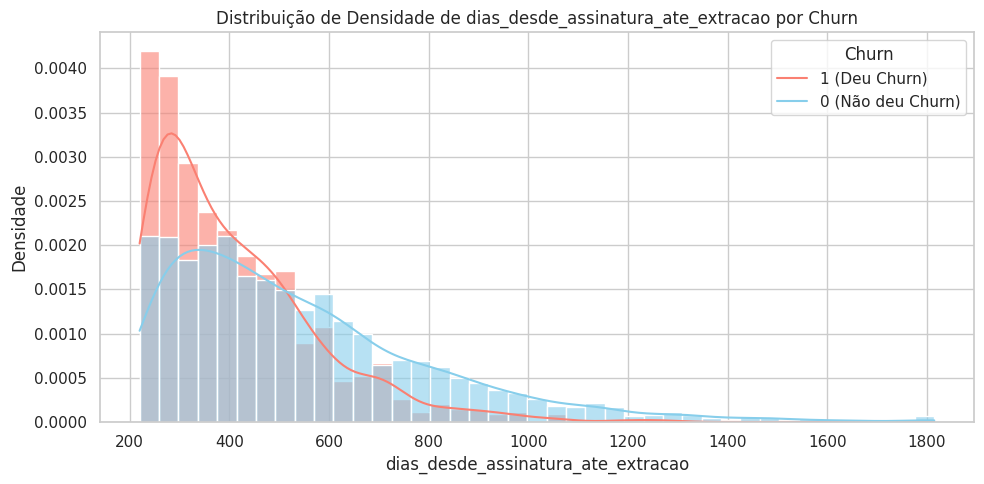

churn,0,1
count,2780.000000,888.000000
mean,542.666187,409.548423
std,265.461831,166.733604
min,220.000000,220.000000
25%,341.000000,282.000000
50%,481.000000,364.500000
75%,673.250000,495.000000
max,1815.000000,1276.000000



==================== ANÁLISE DA VARIÁVEL: recencia ====================


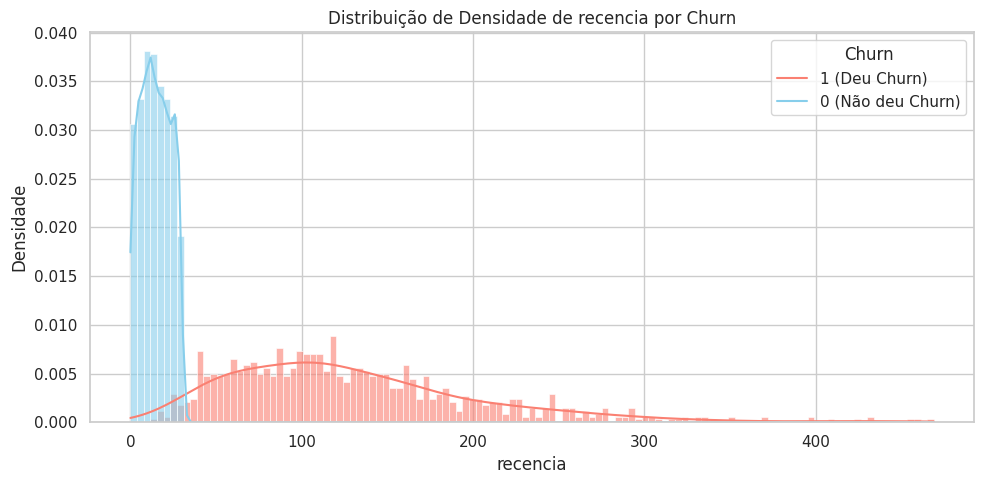

churn,0,1
count,2755.000000,878.000000
mean,14.603993,130.011390
std,8.493044,74.106997
min,0.000000,13.000000
25%,8.000000,75.250000
50%,14.000000,117.000000
75%,22.000000,165.000000
max,29.000000,469.000000



==================== ANÁLISE DA VARIÁVEL: meses_assinatura ====================


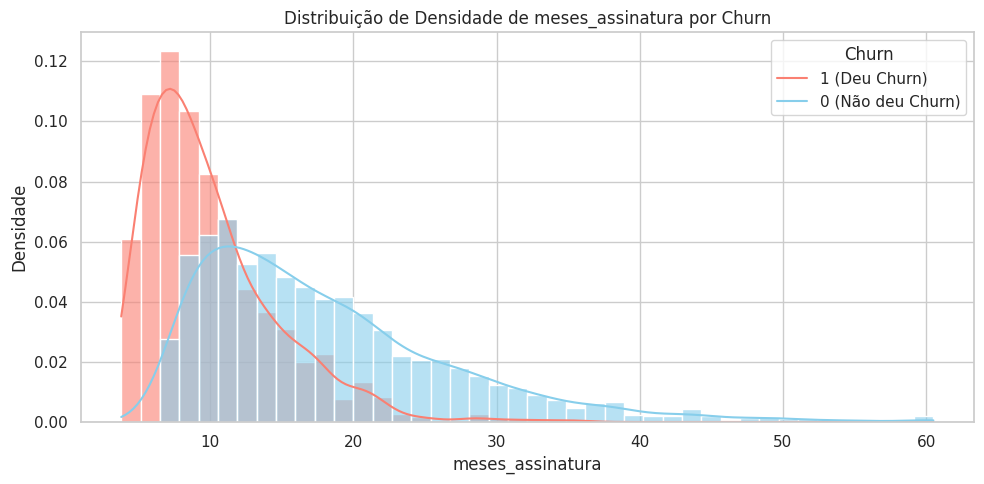

churn,0,1
count,2780.000000,888.000000
mean,18.088873,10.006156
std,8.848728,4.615595
min,7.333333,3.800000
25%,11.366667,6.666667
50%,16.033333,8.900000
75%,22.441667,12.108333
max,60.500000,35.566667



==================== ANÁLISE DA VARIÁVEL: receita_acumulada ====================


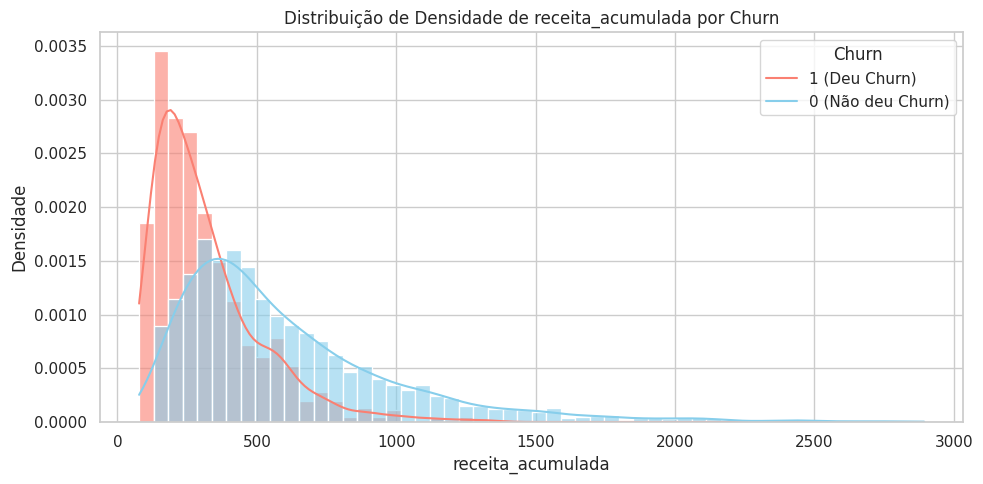

churn,0,1
count,2780.000000,888.000000
mean,605.311556,315.519917
std,396.917467,195.137065
min,145.933333,77.610000
25%,329.013333,172.173333
50%,491.508333,262.680000
75%,762.103333,392.043333
max,2893.756667,1341.600000


In [50]:
sns.set_theme(style="whitegrid")

for var in vars_numericas_churn:
    if var in DF_novo.columns:
        print(f"\n{'='*20} ANÁLISE DA VARIÁVEL: {var} {'='*20}")

        # 1. Histograma de densidade sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=DF_novo,
            x=var,
            hue='churn',
            kde=True,
            stat='density',
            common_norm=False,
            palette={0: 'skyblue', 1: 'salmon'},
            alpha=0.6
        )
        plt.title(f'Distribuição de Densidade de {var} por Churn')
        plt.xlabel(var)
        plt.ylabel('Densidade')
        plt.legend(title='Churn', labels=['1 (Deu Churn)', '0 (Não deu Churn)'])
        plt.tight_layout()
        plt.show()

        # 2. Tabela de estatísticas descritivas agrupada por Churn
        estatisticas = DF_novo.groupby('churn')[var].describe().T
        display(estatisticas)
    else:
        print(f"A coluna '{var}' não foi encontrada em DF_novo.")

#### 19.2: Análise das Variáveis Categóricas vs Churn

Para cada variável categórica, calculamos e mostramos a taxa de churn em porcentagem de forma tabular.

In [51]:
for var in vars_categoricas_churn:
    if var in DF_novo.columns:
        print(f"\n{'='*20} TAXA DE CHURN POR CATEGORIA: {var} {'='*20}")

        # Calculando a taxa de churn por categoria
        tabela_churn = DF_novo.groupby(var)['churn'].agg(
            Total_Clientes='count',
            Total_Churn='sum',
            Taxa_Churn=lambda x: (x.mean() * 100)
        ).round(2)

        # Renomeando coluna para melhor legibilidade
        tabela_churn = tabela_churn.rename(columns={'Taxa_Churn': 'Taxa de Churn (%)'})
        display(tabela_churn)
    else:
        print(f"A coluna '{var}' não foi encontrada em DF_novo.")


==================== TAXA DE CHURN POR CATEGORIA: plano ====================


,Total_Clientes,Total_Churn,Taxa de Churn (%)
plano,,,
básico,1486,404,27.19
padrão,1436,325,22.63
premium,746,159,21.31



==================== TAXA DE CHURN POR CATEGORIA: ciclo ====================


,Total_Clientes,Total_Churn,Taxa de Churn (%)
ciclo,,,
Anual,916,220,24.02
Mensal,2752,668,24.27



==================== TAXA DE CHURN POR CATEGORIA: regiao ====================


,Total_Clientes,Total_Churn,Taxa de Churn (%)
regiao,,,
Centro-Oeste,353,93,26.35
Nordeste,719,172,23.92
Norte,297,76,25.59
Sudeste,1464,338,23.09
Sul,707,174,24.61



==================== TAXA DE CHURN POR CATEGORIA: canal_aquisicao ====================


,Total_Clientes,Total_Churn,Taxa de Churn (%)
canal_aquisicao,,,
google,635,172,27.09
indicação,797,181,22.71
instagram,1125,280,24.89
orgânico,1111,255,22.95


### Passo 20: Segmentação RFM para Streaming (Clientes Ativos)

Vamos construir uma segmentação RFM customizada para a base ativa de clientes do `DF_novo` (`churn == 0`), adaptando os critérios convencionais para engajamento de produto:
* **Recência (R):** Dias desde o último acesso (`recencia`).
* **Frequência (F):** Dias ativos no último mês (`dias_ativos_ult_mes`).
* **Monetário (M):** Valor da mensalidade do plano (`valor_mensal`).

### Passo 20: Segmentação RFM para Streaming (Consolidado)

Para evitar erros de variáveis não definidas no ambiente, unificamos todas as etapas da segmentação RFM em uma única célula contínua de processamento:
1. Filtração de clientes ativos (`churn == 0`) e com `recencia` válida.
2. Divisão por quintis e atribuição de pontuações de 1 a 5 para R, F e M.
3. Geração do código concatenado (ex: `R5F4M3`).
4. Mapeamento e classificação dos clientes nos 5 segmentos solicitados.
5. Consolidação da tabela de volumetria e plotagem do gráfico.

Quantidade de clientes ativos com recência válida: 2755

=== Volumetria dos Segmentos RFM ===


,Contagem,Porcentagem (%)
Segmento_RFM,,
5) Regulares,698,25.34
2) Em risco,564,20.47
3) Novos/Ativos recentes,552,20.04
4) Adormecidos,523,18.98
1) Engajados,418,15.17


/tmp/ipykernel_1134/504703256.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


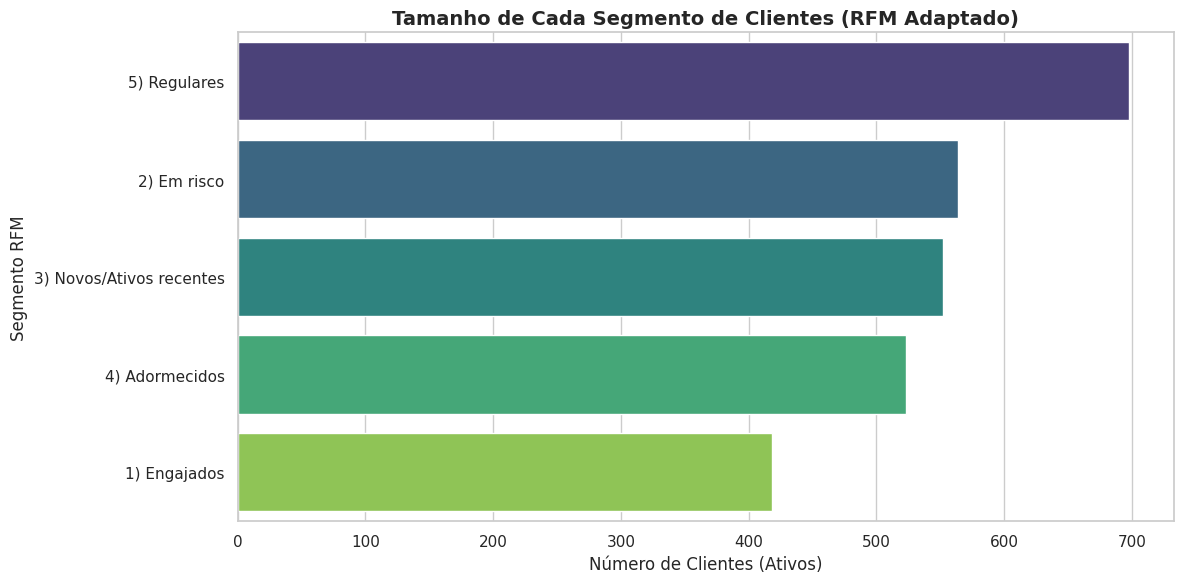

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Filtrar clientes ativos e remover nulos na coluna 'recencia' ---
df_rfm = DF_novo[(DF_novo['churn'] == 0) & (DF_novo['recencia'].notnull())].copy()
print(f"Quantidade de clientes ativos com recência válida: {len(df_rfm)}")

# --- 2. Atribuição de scores de 1 a 5 usando qcut ---
# R: Menores valores de recência recebem nota maior (5)
df_rfm['R'] = pd.qcut(df_rfm['recencia'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# F: Maiores valores de frequência recebem nota maior (5)
df_rfm['F'] = pd.qcut(df_rfm['dias_ativos_ult_mes'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# M: Maiores valores monetários recebem nota maior (5)
# Usando o rank 'first' para contornar o problema de bins idênticos devido aos preços de planos fixos
df_rfm['M'] = pd.qcut(df_rfm['valor_mensal'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Criar Código RFM
df_rfm['RFM_Code'] = "R" + df_rfm['R'].astype(str) + "F" + df_rfm['F'].astype(str) + "M" + df_rfm['M'].astype(str)

# --- 3. Definição dos Segmentos de Clientes ---
def definir_segmento(row):
    r = row['R']
    f = row['F']

    if r >= 4 and f >= 4:
        return '1) Engajados'
    elif r <= 2 and f >= 3:
        return '2) Em risco'
    elif r >= 4 and f <= 2:
        return '3) Novos/Ativos recentes'
    elif r <= 2 and f <= 2:
        return '4) Adormecidos'
    else:
        return '5) Regulares'

df_rfm['Segmento_RFM'] = df_rfm.apply(definir_segmento, axis=1)

# --- 4. Exibição da Volumetria e Porcentagem ---
tabela_segmentos = df_rfm['Segmento_RFM'].value_counts().to_frame(name='Contagem')
tabela_segmentos['Porcentagem (%)'] = ((tabela_segmentos['Contagem'] / len(df_rfm)) * 100).round(2)

print("\n=== Volumetria dos Segmentos RFM ===")
display(tabela_segmentos)

# --- 5. Visualização Gráfica ---
plt.figure(figsize=(12, 6))
sns.barplot(
    data=tabela_segmentos.reset_index(),
    y='Segmento_RFM',
    x='Contagem',
    palette='viridis'
)

plt.title('Tamanho de Cada Segmento de Clientes (RFM Adaptado)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clientes (Ativos)', fontsize=12)
plt.ylabel('Segmento RFM', fontsize=12)
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar clientes ativos e remover nulos na coluna 'recencia'
df_rfm = DF_novo[(DF_novo['churn'] == 0) & (DF_novo['recencia'].notnull())].copy()

print(f"Quantidade de clientes ativos com recência válida: {len(df_rfm)}")

Quantidade de clientes ativos com recência válida: 2755


#### 20.1: Criação de Quintis e Atribuição de Notas (1 a 5)

Aplicaremos a divisão por quintis para cada métrica:
* **Recência:** Nota 5 para menor valor (rótulos de 5 a 1).
* **Frequência:** Nota 5 para maior valor (rótulos de 1 a 5).
* **Monetário:** Nota 5 para maior valor (rótulos de 1 a 5). Como `valor_mensal` possui poucos valores únicos, utilizaremos `duplicates='drop'` para agrupar corretamente em bins exclusivos.

In [54]:
# Gerar os limites dos quintis para cada variável (apenas para exibição)
print("=== Limites dos Quintis por Dimensão ===")
print("\nQuintis de Recência:")
print(df_rfm['recencia'].quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]))

print("\nQuintis de Frequência (Dias Ativos):")
print(df_rfm['dias_ativos_ult_mes'].quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]))

print("\nQuintis de Monetário (Valor Mensal):")
print(df_rfm['valor_mensal'].quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]))

# Atribuição de scores de 1 a 5 usando qcut
# R: Menores valores de recência recebem nota maior (5)
df_rfm['R'] = pd.qcut(df_rfm['recencia'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# F: Maiores valores de frequência recebem nota maior (5)
df_rfm['F'] = pd.qcut(df_rfm['dias_ativos_ult_mes'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# M: Maiores valores monetários recebem nota maior (5)
# Como temos apenas 3 preços possíveis (19.9, 34.9, 55.9), usaremos o ranking caso haja duplicatas em qcut
df_rfm['M'] = pd.qcut(df_rfm['valor_mensal'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Criar Código RFM
df_rfm['RFM_Code'] = "R" + df_rfm['R'].astype(str) + "F" + df_rfm['F'].astype(str) + "M" + df_rfm['M'].astype(str)

display(df_rfm[['cliente_id', 'recencia', 'R', 'dias_ativos_ult_mes', 'F', 'valor_mensal', 'M', 'RFM_Code']].head(10))

=== Limites dos Quintis por Dimensão ===

Quintis de Recência:
0.0     0.0
0.2     6.0
0.4    12.0
0.6    17.0
0.8    23.0
1.0    29.0
Name: recencia, dtype: float64

Quintis de Frequência (Dias Ativos):
0.0     3.0
0.2    11.0
0.4    13.0
0.6    15.0
0.8    17.0
1.0    28.0
Name: dias_ativos_ult_mes, dtype: float64

Quintis de Monetário (Valor Mensal):
0.0    19.9
0.2    19.9
0.4    34.9
0.6    34.9
0.8    55.9
1.0    55.9
Name: valor_mensal, dtype: float64


,cliente_id,recencia,R,dias_ativos_ult_mes,F,valor_mensal,M,RFM_Code
0,5746,2.0,5,15,3,19.9,1,R5F3M1
1,4100,1.0,5,14,3,34.9,2,R5F3M2
3,3454,18.0,2,19,5,19.9,1,R2F5M1
4,1437,15.0,3,11,1,19.9,1,R3F1M1
5,1521,11.0,4,7,1,55.9,4,R4F1M4
7,3842,19.0,2,22,5,34.9,2,R2F5M2
10,4356,20.0,2,15,3,19.9,1,R2F3M1
12,5127,29.0,1,7,1,34.9,2,R1F1M2
15,2624,5.0,5,12,2,34.9,2,R5F2M2
19,3105,4.0,5,13,2,34.9,2,R5F2M2


#### 20.2: Definição dos Segmentos de Clientes

Classificaremos cada cliente conforme as regras solicitadas com base nos scores **R** e **F**:
1. **Engajados**: R >= 4 e F >= 4
2. **Em risco**: R <= 2 e F >= 3
3. **Novos/Ativos recentes**: R >= 4 e F <= 2
4. **Adormecidos**: R <= 2 e F <= 2
5. **Regulares**: demais casos

In [55]:
def definir_segmento(row):
    r = row['R']
    f = row['F']

    if r >= 4 and f >= 4:
        return '1) Engajados'
    elif r <= 2 and f >= 3:
        return '2) Em risco'
    elif r >= 4 and f <= 2:
        return '3) Novos/Ativos recentes'
    elif r <= 2 and f <= 2:
        return '4) Adormecidos'
    else:
        return '5) Regulares'

df_rfm['Segmento_RFM'] = df_rfm.apply(definir_segmento, axis=1)

# Exibir amostra dos segmentos
display(df_rfm[['cliente_id', 'R', 'F', 'M', 'RFM_Code', 'Segmento_RFM']].head(10))

,cliente_id,R,F,M,RFM_Code,Segmento_RFM
0,5746,5,3,1,R5F3M1,5) Regulares
1,4100,5,3,2,R5F3M2,5) Regulares
3,3454,2,5,1,R2F5M1,2) Em risco
4,1437,3,1,1,R3F1M1,5) Regulares
5,1521,4,1,4,R4F1M4,3) Novos/Ativos recentes
7,3842,2,5,2,R2F5M2,2) Em risco
10,4356,2,3,1,R2F3M1,2) Em risco
12,5127,1,1,2,R1F1M2,4) Adormecidos
15,2624,5,2,2,R5F2M2,3) Novos/Ativos recentes
19,3105,5,2,2,R5F2M2,3) Novos/Ativos recentes


#### 20.3: Volumetria e Visualização Gráfica dos Segmentos

Vamos compilar o número total de clientes e a representatividade percentual de cada segmento e gerar um gráfico de barras horizontais.

=== Volumetria dos Segmentos RFM ===


,Contagem,Porcentagem (%)
Segmento_RFM,,
5) Regulares,698,25.34
2) Em risco,564,20.47
3) Novos/Ativos recentes,552,20.04
4) Adormecidos,523,18.98
1) Engajados,418,15.17


/tmp/ipykernel_1134/3222862764.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


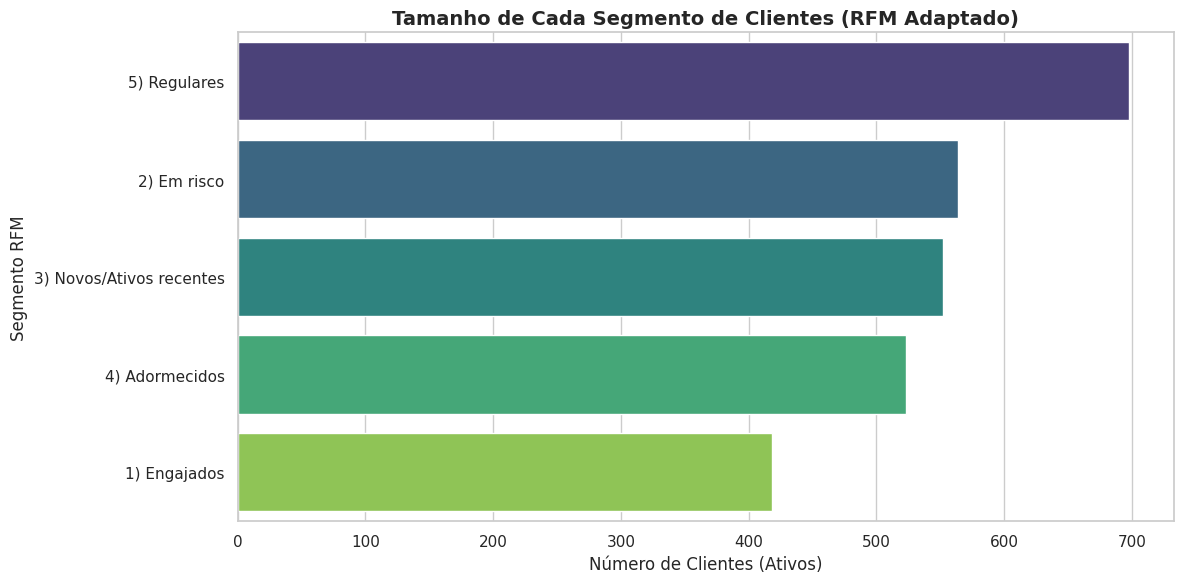

In [56]:
# Tabela consolidada de contagem e porcentagem
tabela_segmentos = df_rfm['Segmento_RFM'].value_counts().to_frame(name='Contagem')
tabela_segmentos['Porcentagem (%)'] = ((tabela_segmentos['Contagem'] / len(df_rfm)) * 100).round(2)

print("=== Volumetria dos Segmentos RFM ===")
display(tabela_segmentos)

# Plotagem do gráfico de barras horizontais
plt.figure(figsize=(12, 6))
sns.barplot(
    data=tabela_segmentos.reset_index(),
    y='Segmento_RFM',
    x='Contagem',
    palette='viridis'
)

plt.title('Tamanho de Cada Segmento de Clientes (RFM Adaptado)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clientes (Ativos)', fontsize=12)
plt.ylabel('Segmento RFM', fontsize=12)
plt.tight_layout()
plt.show()